# **Gerador de Dataset Sintético**

In [ ]:
import pandas as pd
import numpy as np

# 1. Gerando o dataset sintético equilibrado e sem viés com as colunas do seu projeto
np.random.seed(42)
n_samples = 1000

jitter_ms = np.random.exponential(scale=5.0, size=n_samples) + np.random.uniform(0, 15, size=n_samples)
avg = np.random.normal(loc=25.0, scale=15.0, size=n_samples).clip(5, 300)
perda_pacotes_pct = np.random.choice([0.0, 0.5, 1.0, 2.5, 5.0, 12.0], size=n_samples, p=[0.6, 0.15, 0.1, 0.08, 0.05, 0.02])

status_real = []
for j, a, p in zip(jitter_ms, avg, perda_pacotes_pct):
    if p > 2.0 or a > 120.0 or j > 35.0:
        status_real.append('Falha' if (p > 5.0 or a > 180.0) else 'Congestionado')
    else:
        status_real.append('OK')

df_sintetico = pd.DataFrame({
    'measurement_id': range(2000, 2000 + n_samples),
    'timestamp': np.random.randint(1792336800, 1792423200, size=n_samples),
    'data_horario_utc': pd.date_range(start='2026-10-18 15:00:00', periods=n_samples, freq='min').strftime('%Y-%m-%d %H:%M:%S'),
    'prb_id': np.random.choice([1000, 1000000, 1000013, 1000032, 2000005], size=n_samples),
    'from': '192.168.1.1',
    'origem_pais': np.random.choice(['Brasil', 'Holanda', 'Alemanha', 'Austrália', 'Estados Unidos'], size=n_samples),
    'origem_cidade': 'Servidor Local',
    'origem_servidor': 'Probe-Node',
    'target_prb_id': 1001,
    'dst_addr': '193.0.14.129',
    'destino_pais': 'Holanda',
    'avg': avg,
    'perda_pacotes_pct': perda_pacotes_pct,
    'jitter_ms': jitter_ms,
    'status_real': status_real,
    'proto': 'ICMP',
    'type': 'ping'
})

# 2. Conectando ao seu Google Drive e salvando lá dentro
from google.colab import drive
drive.mount('/content/drive')

caminho_drive = '/content/drive/MyDrive/dataset_artigo_sintetico.csv'
df_sintetico.to_csv(caminho_drive, index=False)
print(f"Sucesso! Arquivo gerado e salvo diretamente em: {caminho_drive}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sucesso! Arquivo gerado e salvo diretamente em: /content/drive/MyDrive/dataset_artigo_sintetico.csv


# **Teste com árvore de decisão**


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/dataset_artigo.csv')

--- Informações Básicas do Dataset ---
Total de linhas carregadas: 1000
Colunas disponíveis: ['measurement_id', 'timestamp', 'data_horario_utc', 'prb_id', 'from', 'origem_pais', 'origem_cidade', 'origem_servidor', 'target_prb_id', 'dst_addr', 'destino_pais', 'avg', 'perda_pacotes_pct', 'jitter_ms', 'status_real', 'proto', 'type']

--- Resultados do Modelo (Árvore de Decisão) ---
Acurácia: 0.9950

Relatório de Classificação (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       178
           1       1.00      0.95      0.98        22

    accuracy                           0.99       200
   macro avg       1.00      0.98      0.99       200
weighted avg       1.00      0.99      0.99       200

Matriz de Confusão:
[[178   0]
 [  1  21]]

[Sucesso] Gráfico da árvore salvo como 'arvore_decisao_resultado.png'!


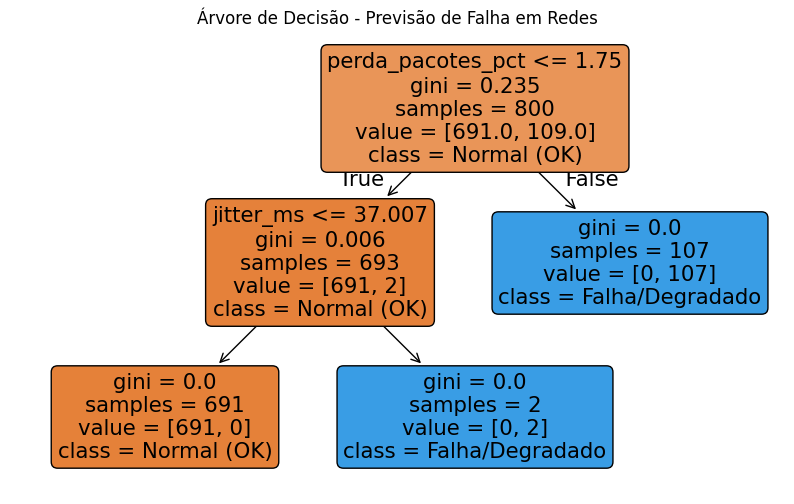

In [ ]:

# 1. Carregar o dataset enviado
df = pd.read_csv('/content/drive/MyDrive/dataset_artigo_sintetico.csv')

print("--- Informações Básicas do Dataset ---")
print(f"Total de linhas carregadas: {len(df)}")
print("Colunas disponíveis:", df.columns.tolist())

# 2. Definir as features (variáveis de entrada) e o target (alvo)
# Usamos as colunas exigidas: jitter, latência (avg) e perda de pacotes
features = ['jitter_ms', 'avg', 'perda_pacotes_pct']
target = 'status_real'

# Mapeando o status real para valores numéricos (0 = OK/Normal, 1 = Falha/Degradado)
# Nota: Caso sua base tenha outras strings como 'Falha', elas serão tratadas aqui.
df['status_num'] = df[target].map({'OK': 0, 'Falha': 1, 'Congestionado': 1}).fillna(0)

X = df[features]
y = df['status_num']

# 3. Dividir em conjunto de Treino (80%) e Teste (20%) com semente fixa
# (Como o dataset de exemplo pode ter poucas linhas, ajustamos o train_test_split de forma segura)
test_size_val = 0.2 if len(df) > 5 else 0.5

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size_val, random_state=42
)

# 4. Criar e treinar a Árvore de Decisão com poda (max_depth) para evitar overfitting
clf = DecisionTreeClassifier(
    max_depth=5,          # Limita a profundidade da árvore
    min_samples_leaf=2,   # Número mínimo de amostras por folha
    random_state=42
)

clf.fit(X_train, y_train)

# 5. Fazer previsões no conjunto de teste
y_pred = clf.predict(X_test)

# 6. Avaliar o desempenho (Métricas exigidas para o artigo)
print("\n--- Resultados do Modelo (Árvore de Decisão) ---")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")

print("Relatório de Classificação (Precision, Recall, F1-Score):")
# Usamos zero_division=0 para evitar avisos caso alguma classe esteja ausente na amostra de teste
print(classification_report(y_test, y_pred, zero_division=0))

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))

# 7. Gerar e salvar a visualização gráfica da árvore para colocar no site
plt.figure(figsize=(10, 6))
plot_tree(
    clf,
    feature_names=features,
    class_names=['Normal (OK)', 'Falha/Degradado'],
    filled=True,
    rounded=True
)
plt.title("Árvore de Decisão - Previsão de Falha em Redes")
plt.savefig("arvore_decisao_resultado.png", dpi=300, bbox_inches='tight')
print("\n[Sucesso] Gráfico da árvore salvo como 'arvore_decisao_resultado.png'!")

# Teste com Random Forest (**Bagging**)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

--- Informações Básicas do Dataset ---
Total de linhas carregadas: 1000
Colunas disponíveis: ['measurement_id', 'timestamp', 'data_horario_utc', 'prb_id', 'from', 'origem_pais', 'origem_cidade', 'origem_servidor', 'target_prb_id', 'dst_addr', 'destino_pais', 'avg', 'perda_pacotes_pct', 'jitter_ms', 'status_real', 'proto', 'type']

--- Resultados do Modelo (Random Forest) ---
Acurácia: 0.9950

Relatório de Classificação (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       178
           1       1.00      0.95      0.98        22

    accuracy                           0.99       200
   macro avg       1.00      0.98      0.99       200
weighted avg       1.00      0.99      0.99       200

Matriz de Confusão:
[[178   0]
 [  1  21]]

Importância dos Atributos na Random Forest:
- jitter_ms: 0.0529
- avg: 0.0365
- perda_pacotes_pct: 0.9106

[Sucesso] Gráfico de importância salvo como 'feature_importance_rf.p

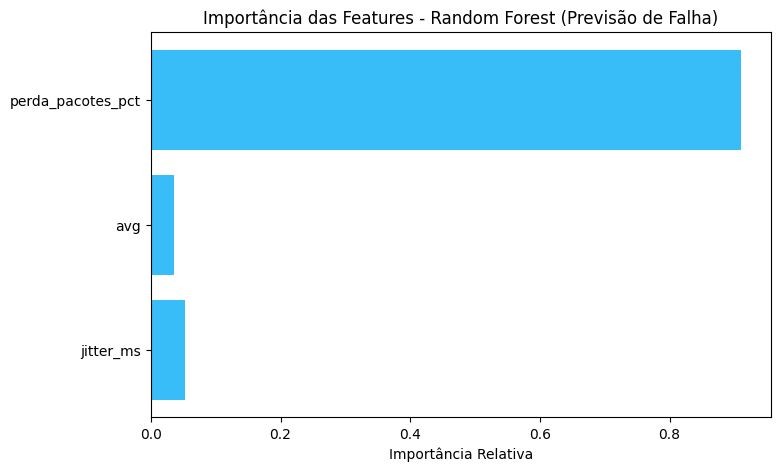

In [ ]:
# 1. Carregar o dataset enviado
df = pd.read_csv('/content/drive/MyDrive/dataset_artigo_sintetico.csv')


print("--- Informações Básicas do Dataset ---")
print(f"Total de linhas carregadas: {len(df)}")
print("Colunas disponíveis:", df.columns.tolist())

# 2. Definir as features (variáveis de entrada) e o target (alvo)
# Utilizando as colunas de telemetria da rede: jitter, latência média e perda de pacotes
features = ['jitter_ms', 'avg', 'perda_pacotes_pct']
target = 'status_real'

# Mapeando o status real para valores numéricos (0 = OK/Normal, 1 = Falha/Degradado)
df['status_num'] = df[target].map({'OK': 0, 'Falha': 1, 'Congestionado': 1}).fillna(0)

X = df[features]
y = df['status_num']

# 3. Dividir em conjunto de Treino (80%) e Teste (20%) com semente fixa
test_size_val = 0.2 if len(df) > 5 else 0.5

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size_val, random_state=42
)

# 4. Criar e treinar a Random Forest (Bagging)
# n_estimators=100 cria uma floresta com 100 árvores em paralelo
rf_clf = RandomForestClassifier(
    n_estimators=100,     # Quantidade de árvores na floresta
    max_depth=8,          # Limita a profundidade máxima de cada árvore
    random_state=42,      # Garante reprodutibilidade
    n_jobs=-1             # Usa todos os núcleos disponíveis da CPU para acelerar o treino
)

rf_clf.fit(X_train, y_train)

# 5. Fazer previsões no conjunto de teste
y_pred = rf_clf.predict(X_test)

# 6. Avaliar o desempenho (Métricas exigidas para o artigo)
print("\n--- Resultados do Modelo (Random Forest) ---")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")

print("Relatório de Classificação (Precision, Recall, F1-Score):")
print(classification_report(y_test, y_pred, zero_division=0))

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))

# 7. (Opcional) Extrair a Importância dos Atributos (Feature Importance)
importances = rf_clf.feature_importances_
print("\nImportância dos Atributos na Random Forest:")
for feat, imp in zip(features, importances):
    print(f"- {feat}: {imp:.4f}")

# Gráfico simples de importância de atributos para salvar e usar no site
plt.figure(figsize=(8, 5))
plt.barh(features, importances, color='#38bdf8')
plt.xlabel("Importância Relativa")
plt.title("Importância das Features - Random Forest (Previsão de Falha)")
plt.savefig("feature_importance_rf.png", dpi=300, bbox_inches='tight')
print("\n[Sucesso] Gráfico de importância salvo como 'feature_importance_rf.png'!")

# **Teste com XGboost abaixo**

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

In [ ]:
# 1. Carregar o dataset sintético gerado
# (Se salvou no Drive, ajuste o caminho para '/content/drive/MyDrive/dataset_artigo_sintetico.csv')
df = pd.read_csv('/content/drive/MyDrive/dataset_artigo_sintetico.csv')

--- Informações do Dataset Sintético ---
Total de linhas: 1000
status_real
OK               869
Congestionado    112
Falha             19
Name: count, dtype: int64

--- Resultados do Modelo (XGBoost) ---
Acurácia: 0.9950

Relatório de Classificação (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       174
           1       1.00      0.96      0.98        26

    accuracy                           0.99       200
   macro avg       1.00      0.98      0.99       200
weighted avg       1.00      0.99      0.99       200

Matriz de Confusão:
[[174   0]
 [  1  25]]

Importância dos Atributos no XGBoost:
- jitter_ms: 0.0346
- avg: 0.0019
- perda_pacotes_pct: 0.9635

[Sucesso] Gráfico de importância do XGBoost salvo como 'feature_importance_xgb.png'!


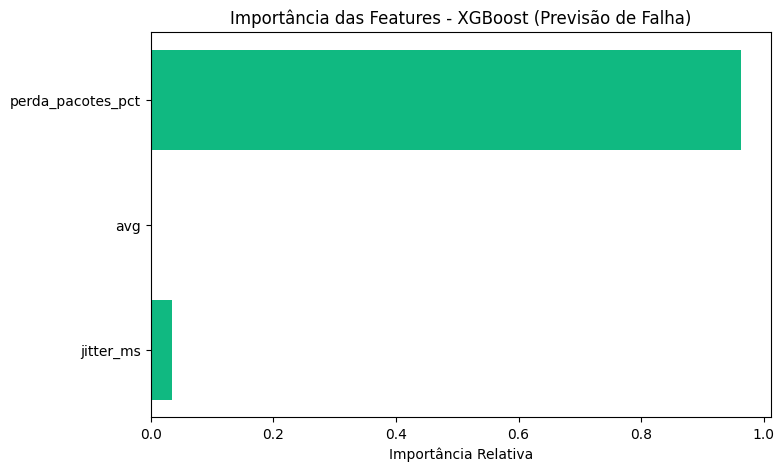

In [ ]:

print("--- Informações do Dataset Sintético ---")
print(f"Total de linhas: {len(df)}")
print(df['status_real'].value_counts())

# 2. Definir features e target (0 = Normal/OK, 1 = Falha/Congestionado)
features = ['jitter_ms', 'avg', 'perda_pacotes_pct']
target = 'status_real'

df['status_num'] = df[target].apply(lambda x: 0 if x == 'OK' else 1)

X = df[features]
y = df['status_num']

# 3. Divisão em Treino (80%) e Teste (20%) com semente fixa e estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Criar e treinar o modelo XGBoost (Gradient Boosting)
# n_estimators e learning_rate controlam o aprendizado sequencial corretivo
xgb_clf = XGBClassifier(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=5,
    reg_lambda=1.0,       # Regularização L2 para evitar overfitting
    random_state=42,
    eval_metric="logloss"
)

xgb_clf.fit(X_train, y_train)

# 5. Fazer previsões no conjunto de teste
y_pred = xgb_clf.predict(X_test)

# 6. Avaliar o desempenho (Métricas para a tabela do site)
print("\n--- Resultados do Modelo (XGBoost) ---")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")

print("Relatório de Classificação (Precision, Recall, F1-Score):")
print(classification_report(y_test, y_pred, zero_division=0))

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))

# 7. Importância dos Atributos (Feature Importance) do XGBoost
importances = xgb_clf.feature_importances_
print("\nImportância dos Atributos no XGBoost:")
for feat, imp in zip(features, importances):
    print(f"- {feat}: {imp:.4f}")

# Gráfico de importância para o site
plt.figure(figsize=(8, 5))
plt.barh(features, importances, color='#10b981')
plt.xlabel("Importância Relativa")
plt.title("Importância das Features - XGBoost (Previsão de Falha)")
plt.savefig("feature_importance_xgb.png", dpi=300, bbox_inches='tight')
print("\n[Sucesso] Gráfico de importância do XGBoost salvo como 'feature_importance_xgb.png'!")

# **Comparação entre os métodos de decisão**

In [ ]:
import time
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:


# 1. Carregar o dataset sintético gerado

df = pd.read_csv('/content/drive/MyDrive/dataset_artigo_sintetico.csv')

# 2. Definir features e target (0 = Normal/OK, 1 = Falha/Congestionado)
features = ['jitter_ms', 'avg', 'perda_pacotes_pct']
target = 'status_real'

df['status_num'] = df[target].apply(lambda x: 0 if x == 'OK' else 1)

X = df[features]
y = df['status_num']

# 3. Mesma divisão de treino (80%) e teste (20%) com semente fixa e estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Dicionário para armazenar os resultados
resultados = []

# Modelos a serem testados
modelos = {
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=5, reg_lambda=1.0, random_state=42, eval_metric="logloss")
}

# 4. Loop de treinamento, medição de tempo e avaliação
for nome, modelo in modelos.items():
    # Medir tempo de treino
    inicio_treino = time.time()
    modelo.fit(X_train, y_train)
    tempo_treino = time.time() - inicio_treino

    # Medir tempo de predição
    inicio_pred = time.time()
    y_pred = modelo.predict(X_test)
    tempo_pred = (time.time() - inicio_pred) * 1000  # em milissegundos

    # Calcular métricas (usando 'macro' ou 'binary' para classes desbalanceadas)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    resultados.append({
        "Modelo": nome,
        "Acurácia": round(acc, 4),
        "Precisão": round(prec, 4),
        "Recall (Sensibilidade)": round(rec, 4),
        "F1-Score": round(f1, 4),
        "Treino (s)": round(tempo_treino, 4),
        "Predição (ms)": round(tempo_pred, 2)
    })

# 5. Criar e exibir a Tabela Comparativa Final
df_comparacao = pd.DataFrame(resultados)

print("==================================================================")
print("             TABELA COMPARATIVA DE DESEMPENHO DOS MODELOS          ")
print("==================================================================")
print(df_comparacao.to_string(index=False))
print("==================================================================")

df_comparacao.to_csv("tabela_comparativa_resultados.csv", index=False)
print("\n[Sucesso] Tabela salva como 'tabela_comparativa_resultados.csv'!")

             TABELA COMPARATIVA DE DESEMPENHO DOS MODELOS          
           Modelo  Acurácia  Precisão  Recall (Sensibilidade)  F1-Score  Treino (s)  Predição (ms)
Árvore de Decisão     0.995       1.0                  0.9615    0.9804      0.0049           2.03
    Random Forest     0.995       1.0                  0.9615    0.9804      0.3840          39.55
          XGBoost     0.995       1.0                  0.9615    0.9804      0.6027           7.31

[Sucesso] Tabela salva como 'tabela_comparativa_resultados.csv'!
